# 04. Prediction intervals (split conformal)

A single number per store-day is not enough for planning: a manager also needs to know how far the
real sales could land from it. This notebook builds **90% prediction intervals** with *split
conformal prediction* and then checks, honestly, how often the real sales fell inside them.

How it works, in plain terms:
1. Fit the model on data up to 42 days before the forecast origin.
2. Forecast the 42 days just before the origin and measure how wrong the model was (on the log
   scale, so a miss is a percentage). These misses are the *calibration errors*.
3. Take the size that 90% of those misses stay under. Wrap the real forecast with that margin.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rossmann_forecast.config import DEFAULT_ORIGINS, HORIZON, MIN_LAG
from rossmann_forecast.data import load_panel
from rossmann_forecast.metrics import all_metrics, wape
from rossmann_forecast.plotting import COLORS, NAMES, apply_style, find_root
from rossmann_forecast.splits import rolling_origin_folds

apply_style()
ROOT = find_root()
panel = load_panel(ROOT / "data")
folds = rolling_origin_folds(DEFAULT_ORIGINS, HORIZON, panel.dates[-1])
final_fold = folds[-1]
print(f"{len(panel.stores):,} stores, {panel.dates[0].date()} to {panel.dates[-1].date()}")

1,115 stores, 2013-01-01 to 2015-07-31


## 1. Calibration: how wrong was the model on the window just before the origin?

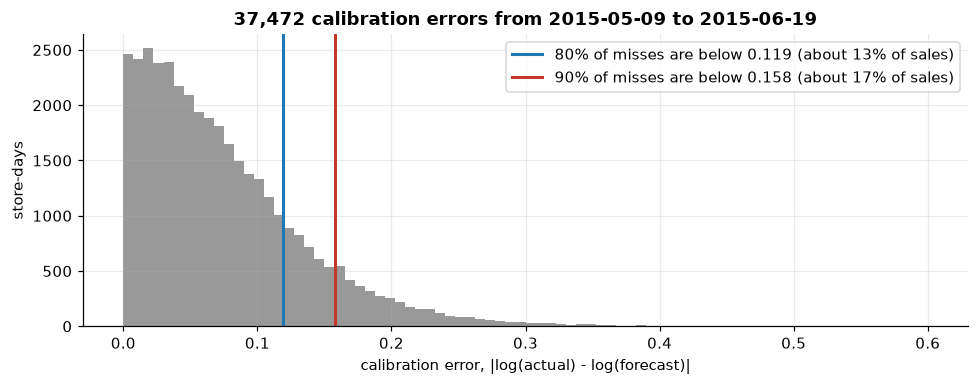

In [2]:
from rossmann_forecast.conformal import conformal_quantile, coverage, interval, log_scores
from rossmann_forecast.features import build_features
from rossmann_forecast.models import fit_lightgbm, forecast_rows, training_rows

origin = final_fold.test_start
cal_origin = origin - pd.Timedelta(days=HORIZON)

feats_cal = build_features(panel, MIN_LAG, known_until=cal_origin)
model_cal = fit_lightgbm(training_rows(feats_cal, cal_origin))
cal = forecast_rows(feats_cal, cal_origin, origin - pd.Timedelta(days=1))
cal = cal[cal["sales"].notna()]
cal_scores = log_scores(cal["sales"].to_numpy(), model_cal.predict_log(cal))

q80, q90 = conformal_quantile(cal_scores, 0.8), conformal_quantile(cal_scores, 0.9)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(cal_scores, bins=80, range=(0, 0.6), color="#999")
for q, lab, c in [(q80, "80%", "#1f77b4"), (q90, "90%", COLORS["lightgbm"])]:
    ax.axvline(q, color=c, lw=2, label=f"{lab} of misses are below {q:.3f} (about {np.expm1(q) * 100:.0f}% of sales)")
ax.set_xlabel("calibration error, |log(actual) - log(forecast)|")
ax.set_ylabel("store-days")
ax.set_title(f"{len(cal_scores):,} calibration errors from {cal_origin.date()} to {(origin - pd.Timedelta(days=1)).date()}")
ax.legend()
fig.tight_layout()
plt.show()

## 2. Forecast the final window and add the margin

In [3]:
feats = build_features(panel, MIN_LAG, known_until=origin)
model = fit_lightgbm(training_rows(feats, origin))
test = forecast_rows(feats, origin, final_fold.test_end)
test = test[test["sales"].notna()].copy()
test["log_pred"] = model.predict_log(test)
test["forecast"] = np.clip(np.expm1(test["log_pred"]), 0, None)
for tag, q in (("80", q80), ("90", q90)):
    test[f"lo{tag}"], test[f"hi{tag}"] = interval(test["log_pred"], q)
for tag in ("80", "90"):
    print(f"{tag}% interval: {coverage(test['sales'], test[f'lo{tag}'], test[f'hi{tag}']) * 100:.1f}% of actual store-days landed inside")

80% interval: 77.1% of actual store-days landed inside
90% interval: 88.0% of actual store-days landed inside


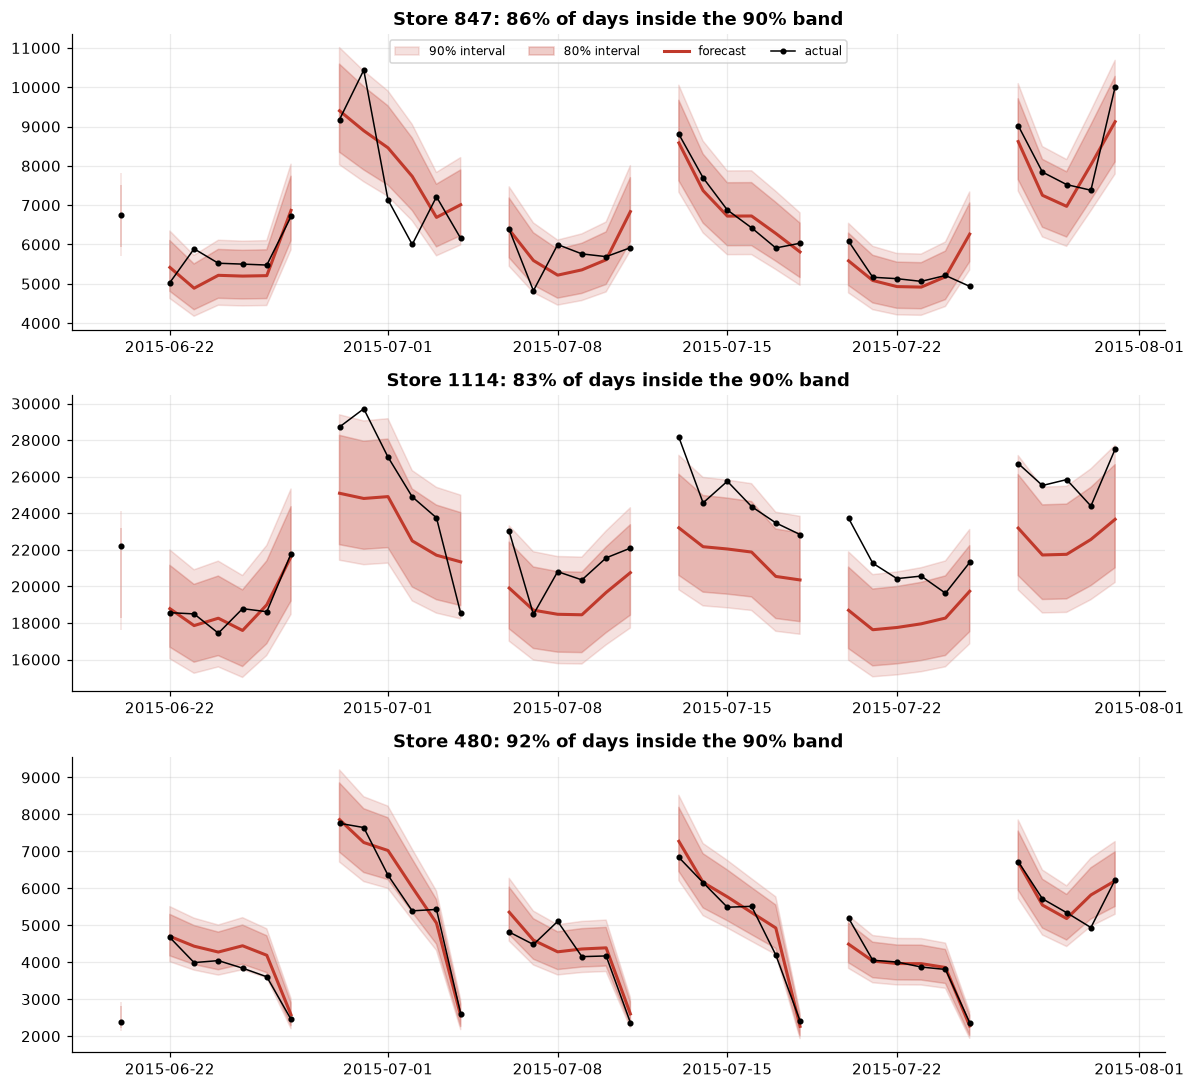

In [4]:
volume = test.groupby("store_id")["sales"].mean().sort_values()
picks = [int(volume.index[len(volume) // 2]), int(volume.index[-1]), int(volume.index[len(volume) // 8])]
fig, axes = plt.subplots(3, 1, figsize=(11, 10))
for ax, s in zip(axes, picks, strict=True):
    g = test[test["store_id"] == s].set_index("date").reindex(pd.date_range(origin, final_fold.test_end))
    ax.fill_between(g.index, g["lo90"], g["hi90"], color=COLORS["lightgbm"], alpha=0.15, label="90% interval")
    ax.fill_between(g.index, g["lo80"], g["hi80"], color=COLORS["lightgbm"], alpha=0.25, label="80% interval")
    ax.plot(g.index, g["forecast"], color=COLORS["lightgbm"], lw=2, label="forecast")
    ax.plot(g.index, g["sales"], "o-", color="black", ms=3, lw=1, label="actual")
    inside = ((g["sales"] >= g["lo90"]) & (g["sales"] <= g["hi90"]))[g["sales"].notna()].mean()
    ax.set_title(f"Store {s}: {inside * 100:.0f}% of days inside the 90% band")
axes[0].legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

## 3. Is the promise kept? Reliability across confidence levels

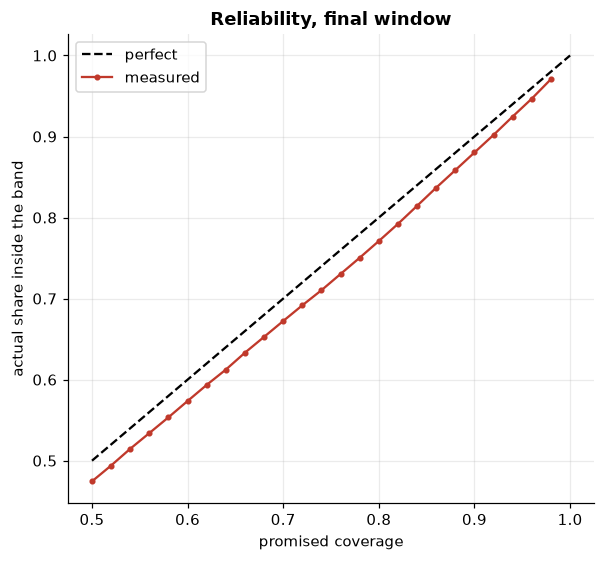

In [5]:
levels = np.linspace(0.5, 0.98, 25)
hit = []
for lv in levels:
    q = conformal_quantile(cal_scores, lv)
    lo, hi = interval(test["log_pred"], q)
    hit.append(coverage(test["sales"], lo, hi))
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0.5, 1], [0.5, 1], color="black", ls="--", label="perfect")
ax.plot(levels, hit, color=COLORS["lightgbm"], marker="o", ms=3, label="measured")
ax.set_xlabel("promised coverage")
ax.set_ylabel("actual share inside the band")
ax.set_title("Reliability, final window")
ax.legend()
fig.tight_layout()
plt.show()

## 4. All three windows, including the one where it falls short

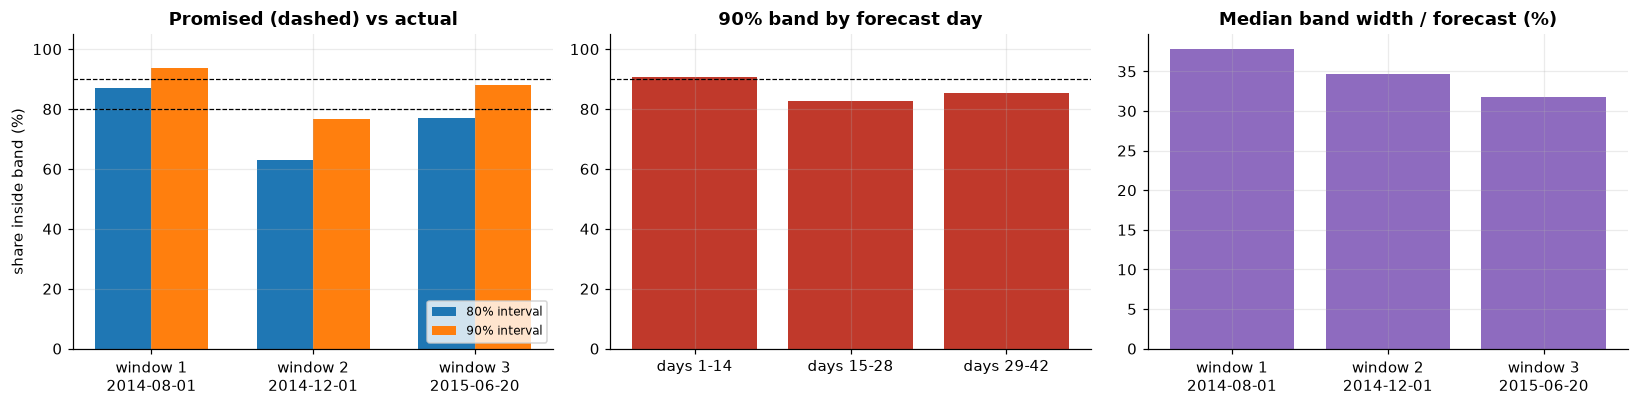

In [6]:
import json

results = json.loads((ROOT / "reports" / "results.json").read_text())
fold_label = {f["fold"]: f"window {f['fold']}\n{f['test_start']}" for f in results["folds"]}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.arange(len(fold_label))
for j, tag in enumerate(("80", "90")):
    block = results["intervals"][tag]
    axes[0].bar(x + (j - 0.5) * 0.35, [p["coverage"] * 100 for p in block["per_fold"]], 0.35, label=f"{tag}% interval")
    axes[0].axhline(int(tag), color="black", ls="--", lw=0.8)
axes[0].set_xticks(x, list(fold_label.values()))
axes[0].set_ylim(0, 105)
axes[0].set_ylabel("share inside band (%)")
axes[0].set_title("Promised (dashed) vs actual")
axes[0].legend(fontsize=8, loc="lower right")
hz = results["intervals"]["90"]["coverage_by_horizon"]
axes[1].bar(list(hz), [v * 100 for v in hz.values()], color=COLORS["lightgbm"])
axes[1].axhline(90, color="black", ls="--", lw=0.8)
axes[1].set_ylim(0, 105)
axes[1].set_title("90% band by forecast day")
widths = [p["median_relative_width"] * 100 for p in results["intervals"]["90"]["per_fold"]]
axes[2].bar(x, widths, color="#8e6bbf")
axes[2].set_xticks(x, list(fold_label.values()))
axes[2].set_title("Median band width / forecast (%)")
fig.tight_layout()
plt.show()

Coverage is close to the promise in the summer windows and too low in the December window. The
method assumes the next window behaves like the one just before it, and Christmas trading does
not. The honest reading: use the bands as a guide for a calm period, and widen them around peaks.